In [77]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from scipy.stats import chi2_contingency

import pandas as pd
import os
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.metrics import r2_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [78]:
df = pd.read_csv("loan_data.csv")
df

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27.0,male,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,female,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,male,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,male,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1


In [79]:
def get_test_train(df, test_size=0.2, random_state=True):
    target = "loan_status"
    X = df.drop(target, axis=1)

    # Robust scaling to handle outliers, based on median and inter-quartile range
    scaler = preprocessing.RobustScaler().fit(X)
    X = scaler.transform(X)

    # Additional check for any remaining infinite values
    X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)

    y = df[target]
    if random_state is True:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size)
    else:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=42
        )
    return X_train, X_test, y_train, y_test

In [80]:
def pre_process_data(df, one_hot_encode=False):
    # Use sklearn Imputers to fill in the categorical and numerical columns
    simple_median = SimpleImputer(strategy="median")
    simple_most_freq = SimpleImputer(strategy="most_frequent")

    num_cols = df.select_dtypes(include=np.number).columns  # numerical data
    cat_cols = df.select_dtypes(
        include=["object", "string"]
    ).columns  # categorical data

    # Handle missing values
    df[num_cols] = simple_median.fit_transform(df[num_cols])
    df[cat_cols] = simple_most_freq.fit_transform(df[cat_cols])

    # Replace infinite values with NaN and then impute
    df = df.replace([np.inf, -np.inf], np.nan)
    df[num_cols] = simple_median.fit_transform(df[num_cols])

    if one_hot_encode:
        O_encoder = OrdinalEncoder()
        df[cat_cols] = O_encoder.fit_transform(df[cat_cols])

    return df

In [81]:
df = pre_process_data(df, True)
X_train, X_test, y_train, y_test = get_test_train(df)

In [82]:
df

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,0.0,4.0,71948.0,0.0,3.0,35000.0,4.0,16.02,0.49,3.0,561.0,0.0,1.0
1,21.0,0.0,3.0,12282.0,0.0,2.0,1000.0,1.0,11.14,0.08,2.0,504.0,1.0,0.0
2,25.0,0.0,3.0,12438.0,3.0,0.0,5500.0,3.0,12.87,0.44,3.0,635.0,0.0,1.0
3,23.0,0.0,1.0,79753.0,0.0,3.0,35000.0,3.0,15.23,0.44,2.0,675.0,0.0,1.0
4,24.0,1.0,4.0,66135.0,1.0,3.0,35000.0,3.0,14.27,0.53,4.0,586.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27.0,1.0,0.0,47971.0,6.0,3.0,15000.0,3.0,15.66,0.31,3.0,645.0,0.0,1.0
44996,37.0,0.0,0.0,65800.0,17.0,3.0,9000.0,2.0,14.07,0.14,11.0,621.0,0.0,1.0
44997,33.0,1.0,0.0,56942.0,7.0,3.0,2771.0,0.0,10.02,0.05,10.0,668.0,0.0,1.0
44998,29.0,1.0,1.0,33164.0,4.0,3.0,12000.0,1.0,13.23,0.36,6.0,604.0,0.0,1.0


<Figure size 1200x500 with 0 Axes>

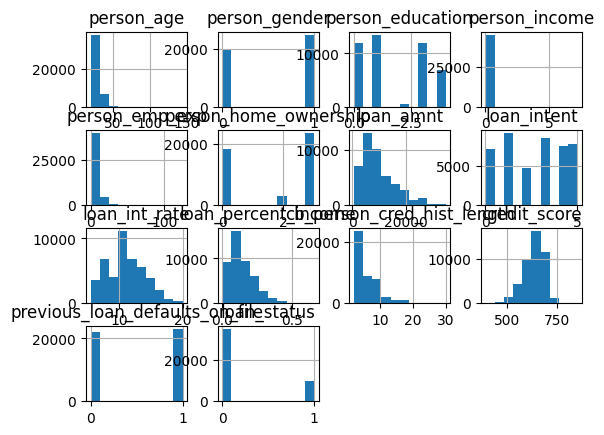

In [83]:
plt.figure(figsize=(12, 5))

df.hist();

In [84]:
# Create logistic regression with liblinear solver
lreg = LogisticRegression()
model = lreg.fit(X_train, y_train)

pred = lreg.predict(X_test[0:1])
print("Prediction for first sample:", pred[0])
print(f"Train accuracy  = {model.score(X_train, y_train):.3}")
print(f"Test  accuracy  = {model.score(X_test, y_test):.3}")

Prediction for first sample: 0.0
Train accuracy  = 0.89
Test  accuracy  = 0.894


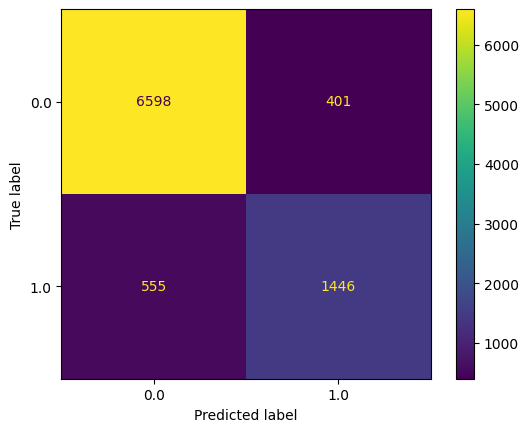

In [85]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, lreg.predict(X_test), labels=lreg.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=lreg.classes_)
disp.plot()
plt.show()

In [32]:
def predict_with_threshold(model, X, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]
    return (proba >= threshold).astype(int)


# Usage
custom_predictions = predict_with_threshold(lreg, X_test, threshold=0.3)

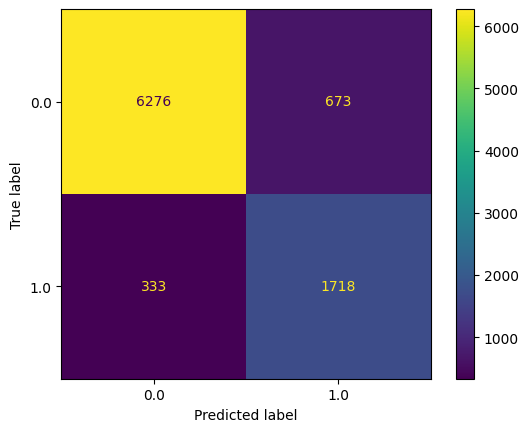

In [38]:
cm = confusion_matrix(
    y_test, predict_with_threshold(lreg, X_test, threshold=0.4), labels=lreg.classes_
)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=lreg.classes_)
disp.plot()
plt.show()

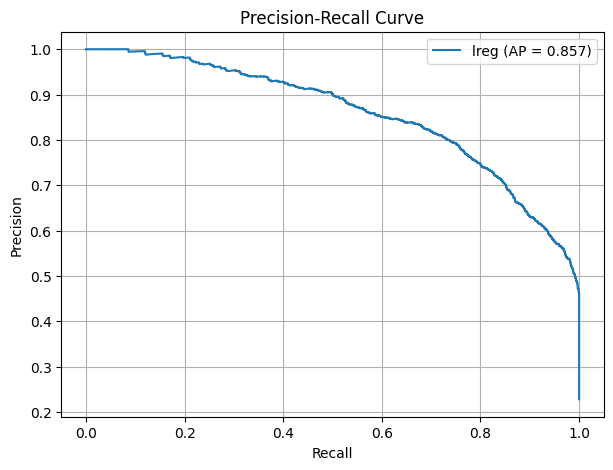

In [55]:
from sklearn.metrics import precision_recall_curve, average_precision_score

y_scores = lreg.predict_proba(X_test)[:, 1]
precision, recall, _ = precision_recall_curve(y_test, y_scores)
average_precision = average_precision_score(y_test, y_scores)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"lreg (AP = {average_precision:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.show()